
## Regression and classification of eye tracker data


In [177]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import pandas as pd
import itertools
import sklearn
from sklearn import linear_model

In [178]:
#X = np.loadtxt('X.txt')
#Y = np.loadtxt('Y.txt')
#bin_vector = np.loadtxt('saccades.txt')

In [179]:
gaze_data = pd.read_csv('database_positions_participant_0.csv')

In [180]:
gaze_data.columns

Index(['Unnamed: 0', 'Eyetracker timestamp', 'Gaze point X', 'Gaze point Y'], dtype='object')

In [181]:
X = gaze_data['Gaze point X']
Y = gaze_data['Gaze point Y']
bin_vector = np.loadtxt('sacc_or_fixation.txt')

Text(0.5, 1.0, 'gaze trajectory representation (first 400 points)')

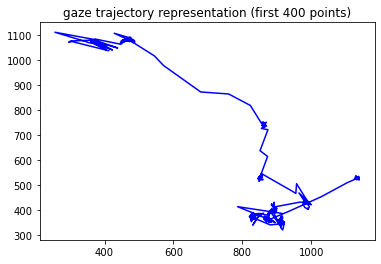

In [182]:
plt.plot(X[0:400],Y[0:400],c='b')
plt.title('gaze trajectory representation (first 400 points)')

Text(0.5, 1.0, 'gaze trajectory representation (first 400 points)')

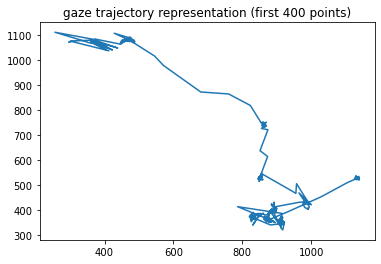

In [183]:
plt.plot(X[0:400],Y[0:400])
#plt.plot(X[0:30],Y[0:30],c='r')
plt.title('gaze trajectory representation (first 400 points)')

In [221]:
np.savetxt("xfig0",X[0:400])
np.savetxt("yfig0",Y[0:400])

In [223]:
fixations = [[0,30],[140,165],[170,200],[220,250],[260,330],[335,360],[370,400]]
saccades = [[30,60],[60,90],[90,120],[120,140],[165,170],[200,210],[210,220],[250,260],[330,335],[360,370]]
np.savetxt("fixations.txt",fixations)
np.savetxt("saccades.txt",saccades)

In [186]:
for i in range(len(fixations)):
    np.savetxt("X_fixation_"+str(i)+".txt",X[fixations[i][0]:fixations[i][1]+1])
    np.savetxt("Y_fixation_"+str(i)+".txt",Y[fixations[i][0]:fixations[i][1]+1])

for i in range(len(saccades)):
    np.savetxt("X_saccades_"+str(i)+".txt",X[saccades[i][0]:saccades[i][1]+1])
    np.savetxt("Y_saccades_"+str(i)+".txt",Y[saccades[i][0]:saccades[i][1]+1])

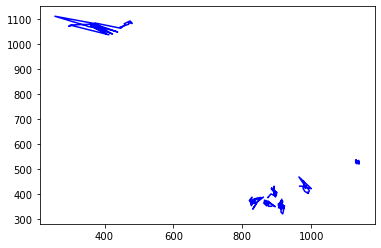

In [187]:
for i in range(len(fixations)):
    plt.plot(X[fixations[i][0]:fixations[i][1]+1],Y[fixations[i][0]:fixations[i][1]+1],c='b')
    np.savetxt("Xfix"+str(i),X[fixations[i][0]:fixations[i][1]+1])
    np.savetxt("Yfix"+str(i),Y[fixations[i][0]:fixations[i][1]+1])

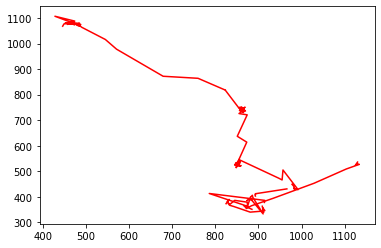

In [188]:
for i in range(len(saccades)):
    plt.plot(X[saccades[i][0]:saccades[i][1]+1],Y[saccades[i][0]:saccades[i][1]+1],c='r')
    np.savetxt("Xsac"+str(i),Y[saccades[i][0]:saccades[i][1]+1])
    np.savetxt("Ysac"+str(i),Y[saccades[i][0]:saccades[i][1]+1])

## Linear interpolation of Y in function of X during saccades (example 1)

In [189]:
index_i = 30
index_f = 60


In [190]:
regx = np.array(X[index_i:index_f]).reshape((-1, 1))
regy = Y[index_i:index_f]

In [191]:
model = sklearn.linear_model.LinearRegression()

In [192]:
model.fit(regx,regy)
intercept = model.intercept_
coef = model.coef_
print(intercept)
print(coef)

1454.2986374940579
[-0.8054019]


In [193]:
model.score(regx, regy)

0.9504619870940828

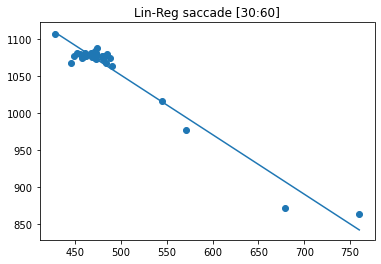

In [194]:
y0 = intercept + coef*min(regx)
y1 = intercept + coef*max(regx)

plt.plot([min(regx),max(regx)],[y0,y1])
plt.scatter(regx,regy)
plt.title("Lin-Reg saccade ["+str(index_i)+ ":" +str(index_f) + "]")
plt.savefig("Lin-Reg" + str(index_i),dpi=500)
np.savetxt("plot-x-sac-1",[min(regx),max(regx)])
np.savetxt("plot-y-sac-1",[y0,y1])
np.savetxt("scatter-x-sac-1",regx)
np.savetxt("scatter-y-sac-1",regy)
#plt.plot(regx,regy)

## Linear interpolation of Y in function of X during saccades (example 2)

In [195]:
index_i = 60
index_f = 90
regx = np.array(X[index_i:index_f]).reshape((-1, 1))
regy = Y[index_i:index_f]
model = sklearn.linear_model.LinearRegression()
model.fit(regx,regy)
intercept = model.intercept_
coef = model.coef_
print(intercept)
print(coef)

2081.3689268957164
[-1.5533525]


In [196]:
model.score(regx, regy)

0.6816449621534442

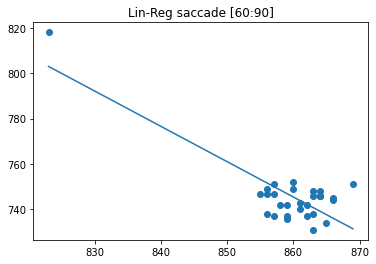

In [197]:
y0 = intercept + coef*min(regx)
y1 = intercept + coef*max(regx)

plt.plot([min(regx),max(regx)],[y0,y1])
plt.scatter(regx,regy)
#plt.plot(regx,regy)
plt.title("Lin-Reg saccade ["+str(index_i)+ ":" +str(index_f) + "]")
plt.savefig("Lin-Reg" + str(index_i),dpi=500)
np.savetxt("plot-x-sac-2",[min(regx),max(regx)])
np.savetxt("plot-y-sac-2",[y0,y1])
np.savetxt("scatter-x-sac-2",regx)
np.savetxt("scatter-y-sac-2",regy)

## Linear interpolation of Y in function of X during saccades (example 3)

In [198]:
index_i = 90
index_f = 120
regx = np.array(X[index_i:index_f]).reshape((-1, 1))
regy = Y[index_i:index_f]
model = sklearn.linear_model.LinearRegression()
model.fit(regx,regy)
intercept = model.intercept_
coef = model.coef_
print(intercept)
print(coef)

-7155.551161915976
[9.0678016]


In [199]:
model.score(regx, regy)

0.6042065729058079

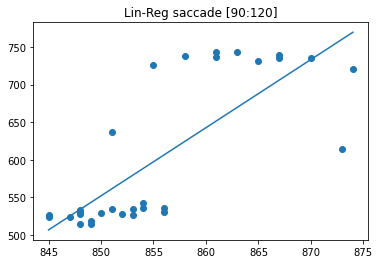

In [200]:
y0 = intercept + coef*min(regx)
y1 = intercept + coef*max(regx)

plt.plot([min(regx),max(regx)],[y0,y1])
plt.scatter(regx,regy)
plt.title("Lin-Reg saccade ["+str(index_i)+ ":" +str(index_f) + "]")
plt.savefig("Lin-Reg" + str(index_i),dpi=500)
np.savetxt("plot-x-sac-3",[min(regx),max(regx)])
np.savetxt("plot-y-sac-3",[y0,y1])
np.savetxt("scatter-x-sac-3",regx)
np.savetxt("scatter-y-sac-3",regy)
#plt.plot(regx,regy)

## Linear interpolation of Y in function of X during fixations (example 1)

In [201]:
index_i = 0
index_f = 30
regx = np.array(X[index_i:index_f]).reshape((-1, 1))
regy = Y[index_i:index_f]
model = sklearn.linear_model.LinearRegression()
model.fit(regx,regy)
intercept = model.intercept_
coef = model.coef_
print(intercept)
print(coef)

1088.0245686372662
[-0.0417585]


model.score(regx, regy)

In [202]:
model.score(regx, regy)

0.026020343099742438

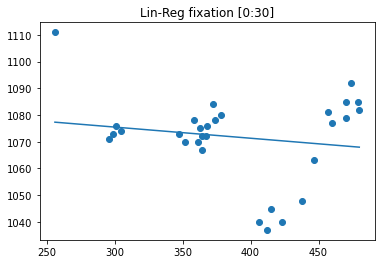

In [203]:
y0 = intercept + coef*min(regx)
y1 = intercept + coef*max(regx)

plt.plot([min(regx),max(regx)],[y0,y1])
plt.scatter(regx,regy)
plt.title("Lin-Reg fixation ["+str(index_i)+ ":" +str(index_f) + "]")
plt.savefig("Lin-Reg" + str(index_i),dpi=500)
np.savetxt("plot-x-fix-1",[min(regx),max(regx)])
np.savetxt("plot-y-fix-1",[y0,y1])
np.savetxt("scatter-x-fix-1",regx)
np.savetxt("scatter-y-fix-1",regy)
#plt.plot(regx,regy)

## Linear interpolation of Y in function of X during fixations (example 2)

In [204]:
index_i = 140
index_f = 165
regx = np.array(X[index_i:index_f]).reshape((-1, 1))
regy = Y[index_i:index_f]
model = sklearn.linear_model.LinearRegression()
model.fit(regx,regy)
intercept = model.intercept_
coef = model.coef_
print(intercept)
print(coef)

1686.7784328642072
[-1.28361544]


In [205]:
model.score(regx, regy)

0.4650763114437393

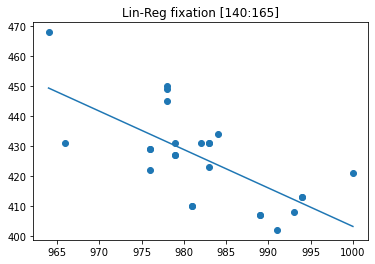

In [206]:
y0 = intercept + coef*min(regx)
y1 = intercept + coef*max(regx)

plt.plot([min(regx),max(regx)],[y0,y1])
plt.scatter(regx,regy)
plt.title("Lin-Reg fixation ["+str(index_i)+ ":" +str(index_f) + "]")
plt.savefig("Lin-Reg" + str(index_i),dpi=500)
np.savetxt("plot-x-fix-2",[min(regx),max(regx)])
np.savetxt("plot-y-fix-2",[y0,y1])
np.savetxt("scatter-x-fix-2",regx)
np.savetxt("scatter-y-fix2",regy)
#plt.plot(regx,regy)

## Linear interpolation of Y in function of X during fixations (example 3)

In [207]:
index_i = 170
index_f = 200
regx = np.array(X[index_i:index_f]).reshape((-1, 1))
regy = Y[index_i:index_f]
model = sklearn.linear_model.LinearRegression()
model.fit(regx,regy)
intercept = model.intercept_
coef = model.coef_
print(intercept)
print(coef)

760.7972920696325
[-0.39651838]


In [208]:
model.score(regx, regy)

0.0432795222032657

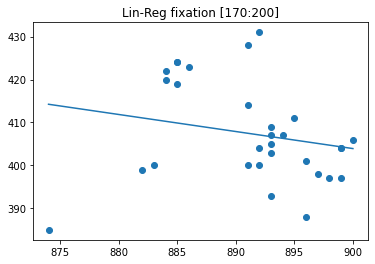

In [209]:
y0 = intercept + coef*min(regx)
y1 = intercept + coef*max(regx)

plt.plot([min(regx),max(regx)],[y0,y1])
plt.scatter(regx,regy)
plt.title("Lin-Reg fixation ["+str(index_i)+ ":" +str(index_f) + "]")
plt.savefig("Lin-Reg" + str(index_i),dpi=500)
np.savetxt("plot-x-fix-3",[min(regx),max(regx)])
np.savetxt("plot-y-fix-3",[y0,y1])
np.savetxt("scatter-x-fix-3",regx)
np.savetxt("scatter-y-fix-3",regy)
#plt.plot(regx,regy)

## Logistic regression 

In [210]:
rsquare = []
results = [] 


for i in range(len(fixations)):
    index_i = fixations[i][0]
    index_f = fixations[i][1]
    regx = np.array(X[index_i:index_f]).reshape((-1, 1))
    regy = Y[index_i:index_f]
    model = sklearn.linear_model.LinearRegression()
    model.fit(regx,regy)
    rsquare.append(model.score(regx, regy))
    results.append(0)

    
for i in range(len(saccades)):
    index_i = saccades[i][0]
    index_f = saccades[i][1]
    regx = np.array(X[index_i:index_f]).reshape((-1, 1))
    regy = Y[index_i:index_f]
    model = sklearn.linear_model.LinearRegression()
    model.fit(regx,regy)
    rsquare.append(model.score(regx, regy))
    results.append(1)

In [211]:
print(rsquare)

[0.026020343099742438, 0.4650763114437393, 0.0432795222032657, 0.1564658690370303, 0.01226363937793773, 0.25670437161765836, 0.040554052439102484, 0.9504619870940828, 0.6816449621534442, 0.6042065729058079, 0.8937722424364501, 0.9723527404844704, 0.553407697765262, 0.02970988264272345, 0.6620133111348776, 0.37678279678357807, 0.9972571147490888]


In [212]:
print(results)

[0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [213]:
rsquare = np.array(rsquare).reshape(-1, 1)

In [214]:
reg = sklearn.linear_model.LogisticRegression(max_iter = 300)

In [215]:
reg.fit(rsquare,results)

LogisticRegression(max_iter=300)

In [216]:
print(model.intercept_)
print(model.coef_)

-212.45359459817308
[0.65278697]


In [217]:
reg.predict_proba(rsquare)

array([[0.55957221, 0.44042779],
       [0.40193833, 0.59806167],
       [0.55339384, 0.44660616],
       [0.51255326, 0.48744674],
       [0.56448369, 0.43551631],
       [0.47622652, 0.52377348],
       [0.55437064, 0.44562936],
       [0.24947493, 0.75052507],
       [0.32926449, 0.67073551],
       [0.35452804, 0.64547196],
       [0.26518522, 0.73481478],
       [0.24357735, 0.75642265],
       [0.37156379, 0.62843621],
       [0.55825293, 0.44174707],
       [0.33558333, 0.66441667],
       [0.43307125, 0.56692875],
       [0.23698373, 0.76301627]])

In [218]:
a = reg.predict_proba(np.arange(-2,3,0.1).reshape(-1, 1))

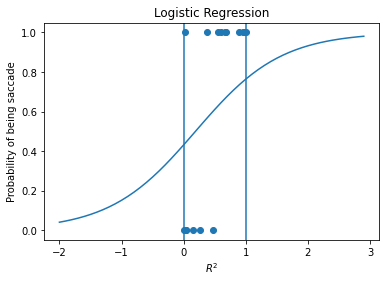

In [219]:
plt.plot(np.arange(-2,3,0.1),np.swapaxes(a, 0, 1)[1])
plt.scatter(rsquare,results)
plt.axvline(x=0, ymin=0, ymax=1)
plt.axvline(x=1, ymin=0, ymax=1)
#plt.axhline(y=0.2, xmin=-2, xmax=3)
#plt.axhline(y=0.4, xmin=-2, xmax=3)
#plt.axhline(y=0.6, xmin=-2, xmax=3)
#plt.axhline(y=0.8, xmin=-2, xmax=3)
plt.xlabel("$R^2$")
plt.ylabel("Probability of being saccade")
plt.title('Logistic Regression')
plt.savefig('Logistic Regression',dpi=500)
np.savetxt("rsquare values",np.arange(-2,3,0.1) )
np.savetxt("probability values",a )

In [220]:
reg.predict(rsquare)

array([0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1])